# Perturbed data to STD model

Plotting results from re-fitting STD model to ovariectomized female data (Fig. 3m, EDFig 6f-k).


## Running fitting: 
### Finding best fits
To find best fits with simulated annealing run: [FitSTD.py](../../modelling/FitSTD.py):
```bash
#Comment out the model use
mode=1 #Use 2D
#mode=0 #Use 0D

#castre
#ovx
parallel --max-procs 40 python3.12 FitSTD.py {1} 1 $mode ovx 1000 0.0 1.0 -1 0 -1 ::: {-120..-1} &
parallel --max-procs 40 python3.12 FitSTD.py {1} 1 $mode ovx 1000 0.0 1.0 -1 0 -1 ::: {-240..-121} &
parallel --max-procs 25 python3.12 FitSTD.py {1} 1 $mode ovx 1000 0.0 1.0 -1 4 -1 ::: {-360..-241} &

```

At the end to combine files run:
```bash
#Analyse simulations
python3.12 FitSTD.py -1000 1 0 ovx -2000 &
```


### Estimating parameter uncertainty with grid search+bootstrapping
To estimate parameter uncertainty run: [FitSTD.py](../../modelling/FitSTD.py):

```bash
#Run grid search with bootstraps
parallel --max-procs 120 python3.12 FitSTD.py {1} 1 $mode ovx 1000 0.0 1.0 -1 0 -1 ::: {0..15000} &

#Analyse simulations
python3.12 FitSTD.py -1000 1 0 ovx 1000 &
```

In [ ]:
#Imports
import numpy as np
import matplotlib.pyplot as plt
import sys
import pickle

sys.path.append("../../analysis/")
sys.path.append("../../sim/")
sys.path.append("../../fit/")
sys.path.append("../../plot/")


from tissue import *
import tissplot as tplt
import matplotlib.path as mplPath
import analysis
import datasets as ds 
import tiss_optimize as topt
import sim_model
import os
import custom_metrics as cmet



#Metrics
ksdists  = {'dist': ['S2like.basalCS', 'S2like.supraCS'], 'dist_metric': 'ksd', 'name': 'ksd_b_sb'}
k1dists  = {'dist': ['S2like.basalCS'], 'dist_metric': 'ksd', 'name': 'ksd_bas'}

ll_dist_STD = {'dist': ['Slike.fullbasalCS', 'Slike.fullsupraCS',
                    'Tlike.fullbasalCS', 'Tlike.fullsupraCS',
                    'Dlike.fullbasalCS', 'Dlike.fullsupraCS', 
                    'S2like.xfrac'], 
                    'dist_metric': 'lLL', 'name': 'll_STD'}

ll_dist_SPD = {'dist': ['S4like.fullbasalCS', 'S4like.fullsupraCS',
                    'CPlike.fullbasalCS', 'CPlike.fullsupraCS',
                    'Dlike.fullbasalCS', 'Dlike.fullsupraCS'], 
                    'dist_metric': 'lLL', 'name': 'll_SPD'}
T0 = 50
mets = [ll_dist_SPD, ll_dist_STD, ksdists, k1dists] 
compute_kwargs = {'Dlike': {'containsBasal': False}}
toCalculate = ['basalCS', 'S4like.basalCS', 'S4like.supraCS', 'CPlike.basalCS', 'CPlike.supraCS', 'Dlike.basalCS', 'Dlike.supraCS',
               'Tlike.basalCS', 'Tlike.supraCS', 'Slike.basalCS', 'Slike.supraCS', 'S2like.basalCS', 'S2like.supraCS',
               'T3like.basalCS', 'T3like.supraCS', 'S2like.xfrac', 'Slike.xfrac', 'Tlike.xfrac', 'Dlike.xfrac',
               'S4like.lcd', 'T3like.lcd', 'CPlike.lcd', 'Dlike.lcd', 'Slike.lcd', 'Tlike.lcd', 'S2like.lcd',
               'S4like.pers', 'T3like.pers', 'CPlike.pers', 'Dlike.pers', 'Slike.pers', 'Tlike.pers', 'S2like.pers',
               'supraCS']


from matplotlib import rcParams
# Set global font size for all axes
rcParams['axes.labelsize'] = 12
rcParams['xtick.labelsize'] = 10
rcParams['ytick.labelsize'] = 10
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 10  # General font size
rcParams['text.usetex'] = False
rcParams['font.family'] = 'sans-serif'
rcParams['font.sans-serif'] = ['Arial']
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 3
rcParams['lines.linewidth']  = 1.5



In [ ]:
'''  
    Getting best fits & parameter uncertainties from bootstrapping
'''

def boot_stats_STD(s0, met, best_fit):
    boot_stats = s0.boot_stats(met).T

    boot_stats['rhoS'] = best_fit['rhoS']
    boot_stats['tscale'] = -boot_stats[met + ':tscale']
    boot_stats['tau'] = 100
    boot_stats['CVd_S'] = best_fit['CVd_S']
    boot_stats['corrST'] = best_fit['corrST']
    boot_stats['corrTD'] = best_fit['corrTD']

    boot_stats['mu'] = ((boot_stats['q']-2)*boot_stats['rhoS']*boot_stats['tau'] + boot_stats['tau']*(1-boot_stats['rhoS']))/(boot_stats['rhoS']*(3-boot_stats['q']))#/boot_stats['tau']*boot_stats['tscale']
    boot_stats['rhoT1'] = boot_stats['tau']/(boot_stats['tau'] + ((3 - boot_stats['q'])*boot_stats['mu'] + (2 - boot_stats['q'])*boot_stats['tau']))
    boot_stats['rhoT2'] = boot_stats['tau']*(1-boot_stats['q'])/(boot_stats['tau'] + ((3 - boot_stats['q'])*boot_stats['mu'] + (2 - boot_stats['q'])*boot_stats['tau']))
    boot_stats['rhoD'] = boot_stats['mu']*(3-boot_stats['q'])/(boot_stats['tau'] + ((3 - boot_stats['q'])*boot_stats['mu'] + (2 - boot_stats['q'])*boot_stats['tau']))
    boot_stats['mu1'] = boot_stats['mu']
    boot_stats['mu'] = ((boot_stats['q']-2)*boot_stats['rhoS']*boot_stats['tau'] + boot_stats['tau']*(1-boot_stats['rhoS']))/(boot_stats['rhoS']*(3-boot_stats['q']))/boot_stats['tau']*boot_stats['tscale']
    boot_stats['rhoT'] = boot_stats['rhoT1'] + boot_stats['rhoT2']
    boot_stats = boot_stats[['tscale', 'mu', 'shed', 'r', 'q', 'rhoS', 'rhoT1', 'rhoT2', 'rhoD', 'rhoT', 'CVd_S', 'CVd_D', 'corrST', 'corrTD', 'corrDD', 'corrSS']]
    return boot_stats

ncells = 1000
tau = 100.0
cST = 1.0
cTD = 0.0
cvS = 1.0
L = 20
hilln = 0.0
ncores = 1

T = -30



cols = {'M': 'r', 'F': 'b', 'castre': 'purple', 'notchF': 'b', 'notchM': 'r', 'lgr6F': 'b', 'lgr6M': 'r'}
sexname = {'M': 'M', 'F': 'F', 'castre': 'cM', 'notchF': 'nF', 'notchM': 'nM', 'lgr6F': 'lF', 'lgr6M': 'lM'}

sim_datasets = {}
exp_datasets = {}
best_fits = {}

all_boots_sex = {}


for sex in ['ovx']:
    if sex == 'M':
        exp_file = '../../experiment/homeo/data_ctr_M.pkl'
        rhoS = 0.3
        cv_sb = 1.0
        q = 0.55
        r = 0.15
    elif sex == 'F':
        exp_file = '../../experiment/homeo/data_ctr_F.pkl'
        rhoS = 0.275
        cv_sb = 0.1   
        q = 1.0 #0.75
        r = 0.125
    elif sex == 'castre':
        exp_file = '../../experiment/castre/data_castre.pkl'
        rhoS = 0.275
        cv_sb = 1.0    
        q = 0.75
        r = 0.1
    elif sex == 'ovx': 
        exp_file = '../../experiment/ovx/data_Ovx.pkl'
        rhoS = 0.32
        cv_sb = 1.0
        q = 1.0
        r = 0.2
        tscale_inc_times = np.arange(1,5)

    for mode in [0]:
        print(ncores, mode, sex)

        if mode == 0:
            savefolder = 'modelling/ST2D_0D_finale_boots/'
            savefolder1 = 'modelling/ST2D_0D_finale/'
            nseeds = 1
            s0 = topt.sim_anneal(sim_model.ST2D_0D, { 'r': [r],
                                                'CVd_D': [1.0],
                                                'corrSS': [0.0],
                                                'corrDD': [0.0],
                                                'q': [q]},
                                params = {'tau': tau, 'refractT': -1, 'corrTT': -1.0,
                                        'CVd_T': -1.0, 'corrTD': cTD, 'rhoS': rhoS,
                                        'CVd_S': cvS, 'corrST':  cST}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate,
                        move_seed = np.abs(0),  use_linear = ['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrST', 'corrDD', 'corrSS'],
                        move_sizes =     {'r': 0.025, 'rhoS':  0.025, 'q': 0.025, 'CVd_S':  0.05, 'CVd_D':  0.05, 'corrST':  0.05, 'corrDD':  0.05, 'corrSS':  0.05},
                        free_param_min = {'r': 0.00, 'rhoS':   0.1, 'q':  0.0, 'CVd_S':  0.0, 'CVd_D':  0.0, 'corrST':  0.0, 'corrDD':  0.0, 'corrSS':  0.0},
                        free_param_max = {'r': 1.00, 'rhoS':   1.0, 'q':  1.01, 'CVd_S': 1.04, 'CVd_D': 1.04, 'corrST': 1.04, 'corrDD': 1.04, 'corrSS': 1.04})
        elif mode == 1:
            savefolder = 'modelling/ST2D_2D_finale_boots/'
            savefolder1 = 'modelling/ST2D_2D_finale/'
            nseeds = ncores
            s0 = topt.sim_anneal(sim_model.ST2D_size, { 'r': [r],
                                                'CVd_D': [1.0],
                                                'corrSS': [1.0],
                                                'corrDD': [1.0],
                                                'q': [q]},
                                params = {'tau': tau, 'refractT': -1, 'corrTT': -1.0,
                                        'CVd_T': -1.0, 'corrTD': cTD, 'rhoS': rhoS,
                                        'CVd_S': cvS, 'corrST':  cST, 
                                        'L': L, 'hilln': hilln}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate,
                        move_seed = np.abs(0),  use_linear = ['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrST', 'corrDD', 'corrSS'],
                        move_sizes =     {'r': 0.025, 'rhoS':  0.025, 'q': 0.025, 'CVd_S':  0.05, 'CVd_D':  0.05, 'corrST':  0.05, 'corrDD':  0.05, 'corrSS':  0.05},
                        free_param_min = {'r': 0.00, 'rhoS':   0.1, 'q':  0.0, 'CVd_S':  0.0, 'CVd_D':  0.0, 'corrST':  0.0, 'corrDD':  0.0, 'corrSS':  0.0},
                free_param_max = {'r': 1.00, 'rhoS':   1.0, 'q':  1.01, 'CVd_S': 1.04, 'CVd_D': 1.04, 'corrST': 1.04, 'corrDD': 1.04, 'corrSS': 1.04})
    
        
        s0.load_existing(tsteps = T, ncells = ncells, savefolder = savefolder1, 
                        tscalevals = -np.arange(4,15,0.05), shedvals = -np.arange(0.45, 1.05, 0.05), 
                        postopt_params = {'sbas_cv': [cv_sb]})
        for met in ['ll_SPD']: # 'll_STD', 'ksd_bas', 'ksd_b_sb'
            best_fits[(savefolder1, sex, met)] = s0.best_fit(met)
            #print(s0.sim_save_name(T, ncells, int(best_fits[(savefolder1, sex, met)].name), 0))
            #print(best_fits[(savefolder, sex, met)])        
        
        s0.load_existing(tsteps = T, ncells = ncells, savefolder = savefolder, 
                        tscalevals = -np.arange(4,15,0.05), shedvals = -np.arange(0.45, 1.05, 0.05), 
                        postopt_params = {'sbas_cv': [cv_sb]})        
        
        #s0.searchspace = s0.searchspace[s0.searchspace['corrTD'] == 0.0]

        for met in ['ll_SPD']: # 'll_STD', 'ksd_bas', 'ksd_b_sb'
            print(sex, s0.searchspace[met].min(), met)
            best_fits[(savefolder, sex, met)] = s0.best_fit(met)
            print(s0.sim_save_name(T, ncells, int(best_fits[(savefolder1, sex, met)].name), 0))
            print('tscale = ', best_fits[(savefolder1, sex, met)]['tscale'])
            boot_stats = boot_stats_STD(s0, met, best_fits[(savefolder, sex, met)])
            #print(s0.boot_stats(met).to_markdown())        
            #print(boot_stats.to_string(float_format=lambda x: f"{x:.3f}"))
            print(boot_stats.to_markdown())

            b = s0.searchspace['ll_SPD:boot_costs'].values
            nboots = len(b[0])
            all_boots = np.array([b1 if np.ndim(b1) > 0 else np.ones(nboots)*1e10 for b1 in b])

            all_boots_sex[sex] = all_boots

1 0 ovx
ovx 3821.5066170957366 ll_SPD
hrun_ST2D_0D_t_-30_n_1000_CVd_D_1.0_CVd_S_1.0_CVd_T_-1.0_corrDD_0.9_corrSS_0.75_corrST_1.0_corrTD_0.0_corrTT_-1.0_q_0.45_r_0.15_refractT_-1.0_rhoS_0.32_tau_100.0_seed_0.pkl
tscale =  -5.45
|          |   tscale |         mu |     shed |         r |        q |   rhoS |   rhoT1 |    rhoT2 |     rhoD |     rhoT |   CVd_S |   CVd_D |   corrST |   corrTD |   corrDD |   corrSS |
|:---------|---------:|-----------:|---------:|----------:|---------:|-------:|--------:|---------:|---------:|---------:|--------:|--------:|---------:|---------:|---------:|---------:|
| Best     |  5.45    |  2.03626   | 3.27     | 0.225     | 0.725    |   0.32 |    0.32 | 0.088    | 0.272    | 0.408    |     0.5 |     0.9 |        1 |        0 | 0.5      | 0.4      |
| Mean     |  4.271   |  1.83322   | 3.0128   | 0.1365    | 0.8135   |   0.32 |    0.32 | 0.05968  | 0.30032  | 0.37968  |     0.5 |     1   |        1 |        0 | 0.435    | 0.305    |
| Median   |  4.25    |  

In [3]:
best_fits.keys()

dict_keys([('modelling/ST2D_0D_finale/', 'ovx', 'll_SPD'), ('modelling/ST2D_0D_finale_boots/', 'ovx', 'll_SPD')])

1 0 ovx
ovx 3821.5066170957366 ll_SPD
hrun_ST2D_0D_t_-30_n_1000_CVd_D_0.9_CVd_S_0.5_CVd_T_-1.0_corrDD_0.5_corrSS_0.4_corrST_1.0_corrTD_0.0_corrTT_-1.0_q_0.725_r_0.225_refractT_-1.0_rhoS_0.32_tau_100.0_seed_0.pkl
tscale: -5.45
τ range: 1.3333333333333333 to 140.0
shed: -0.6 refract: 0.0 cv: 1.0
Already cropped
Already cropped


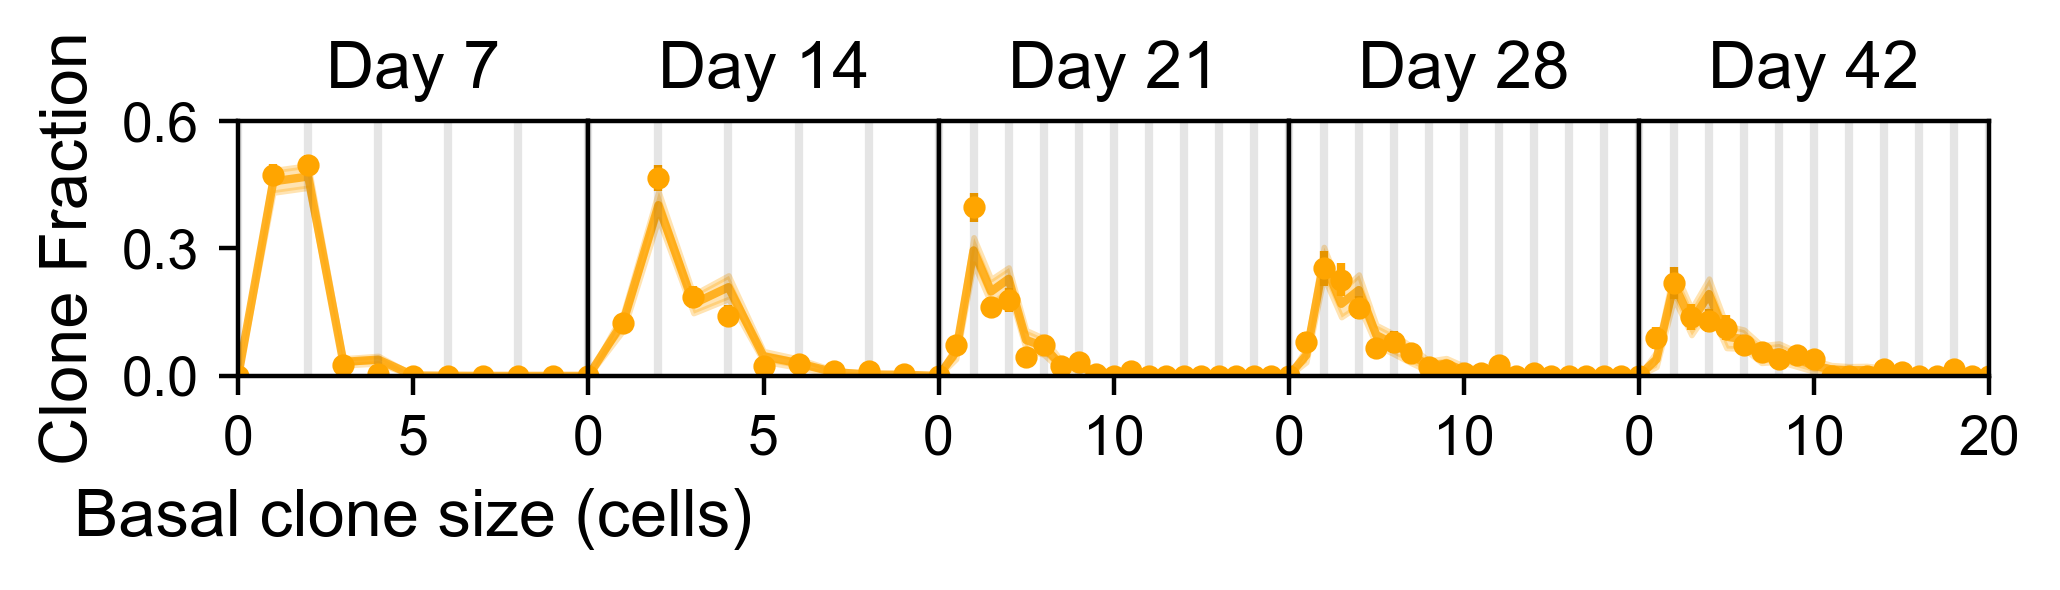

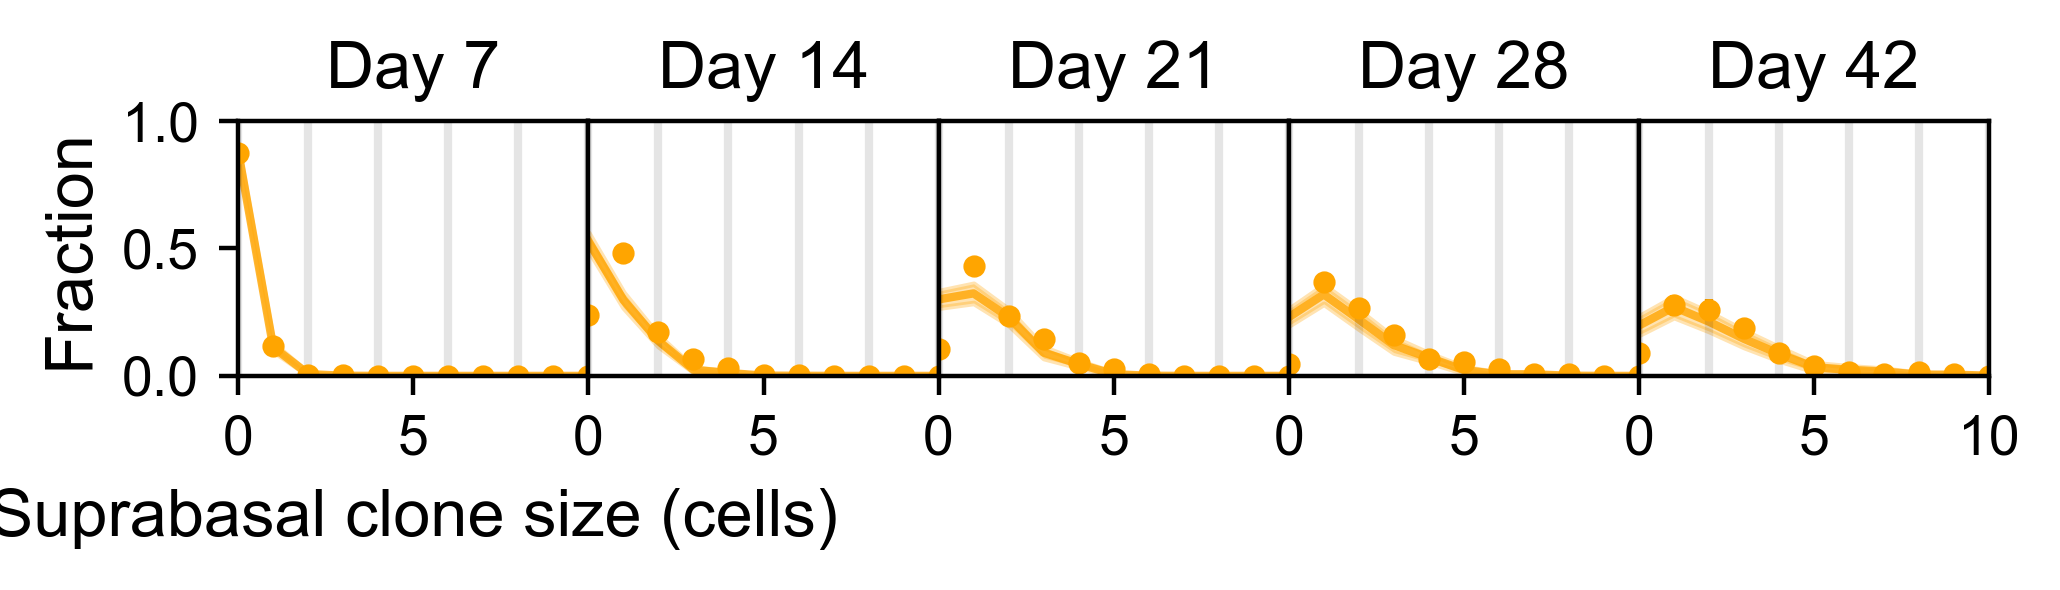

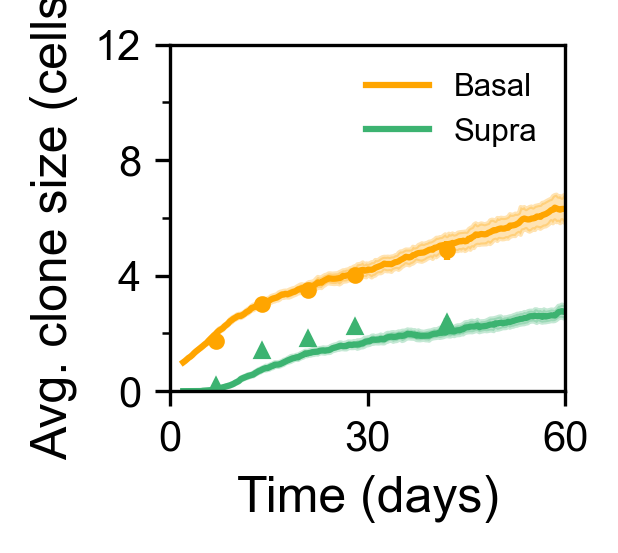

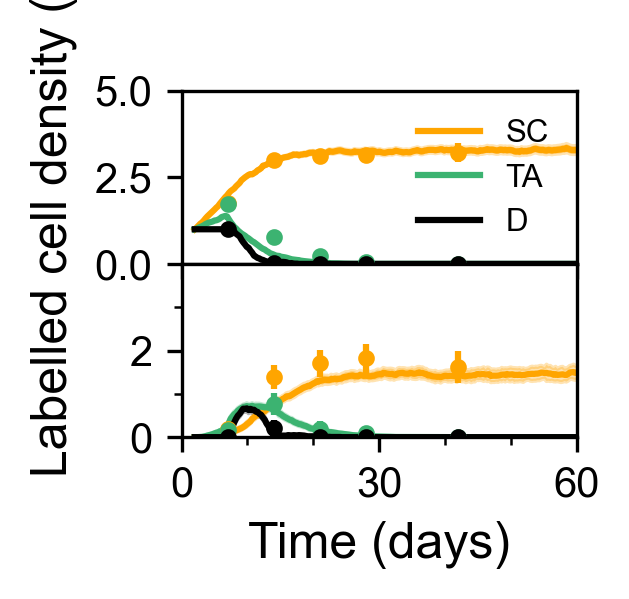

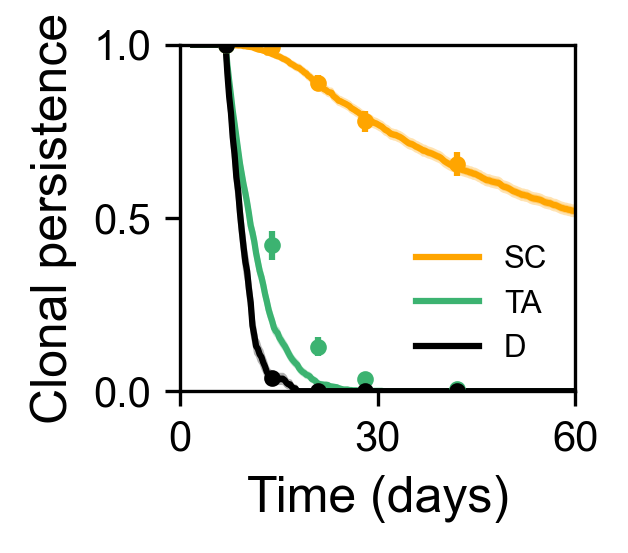

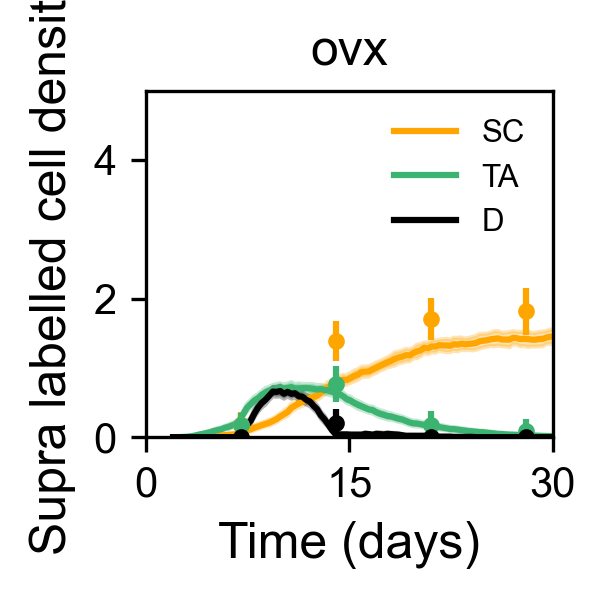

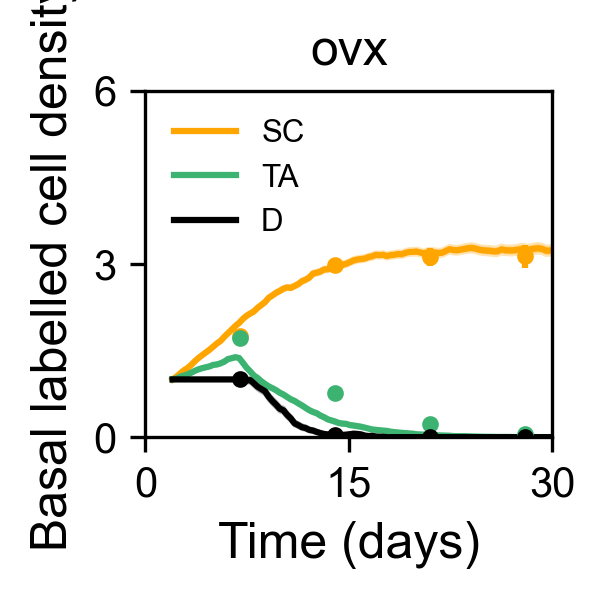

1 0 mcM
mcM 1514.6729381245286 ll_SPD
hrun_ST2D_0D_t_-30_n_1000_CVd_D_0.25_CVd_S_0.75_CVd_T_-1.0_corrDD_0.7_corrSS_0.7_corrST_1.0_corrTD_0.0_corrTT_-1.0_q_0.875_r_0.1_refractT_-1.0_rhoS_0.21_tau_100.0_seed_0.pkl
tscale: -4.15
τ range: 0.8666666666666667 to 140.0
shed: -0.9 refract: 0.0 cv: 0.25
Already cropped
Already cropped


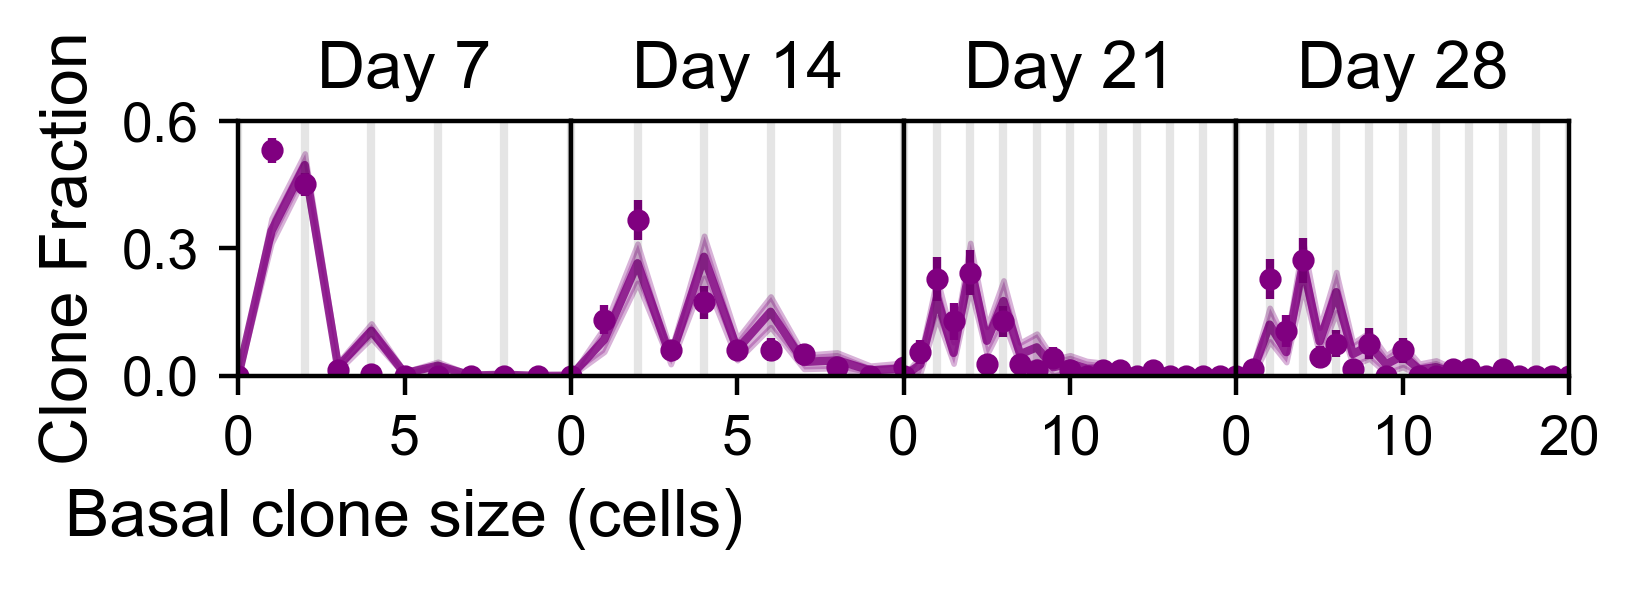

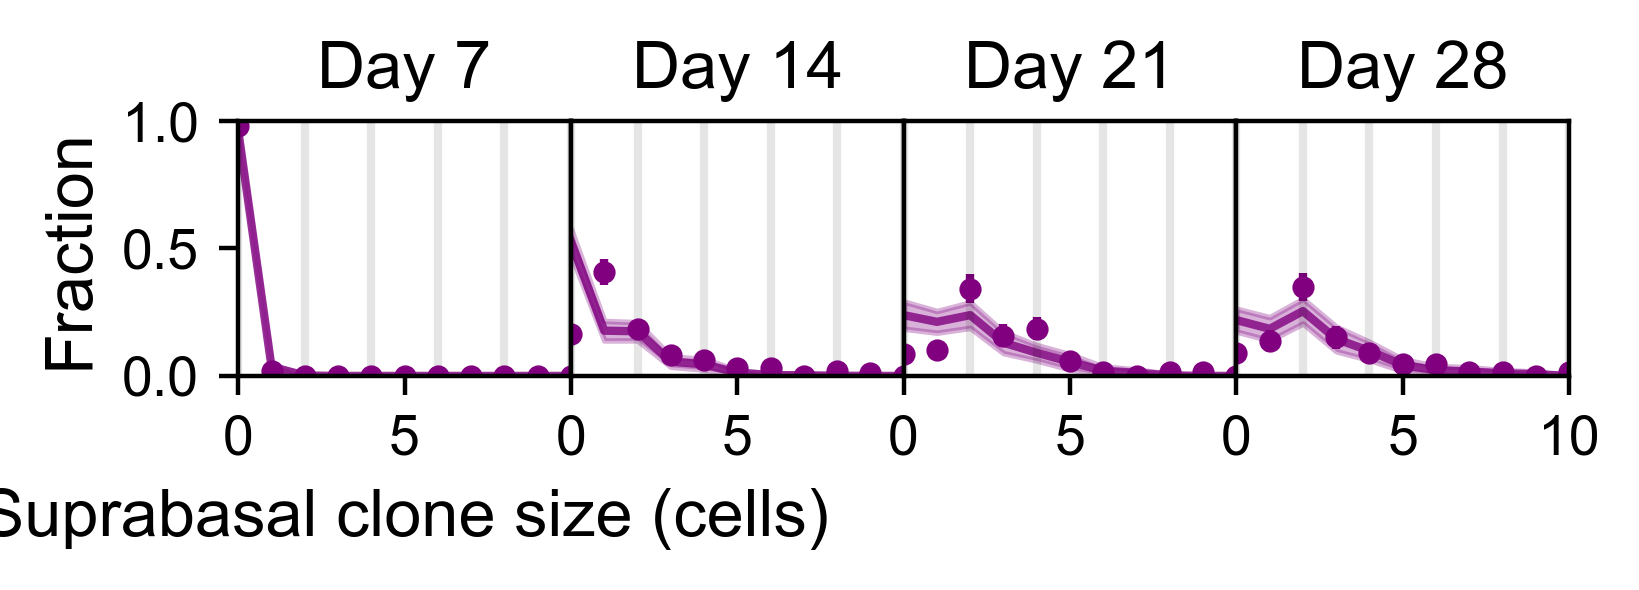

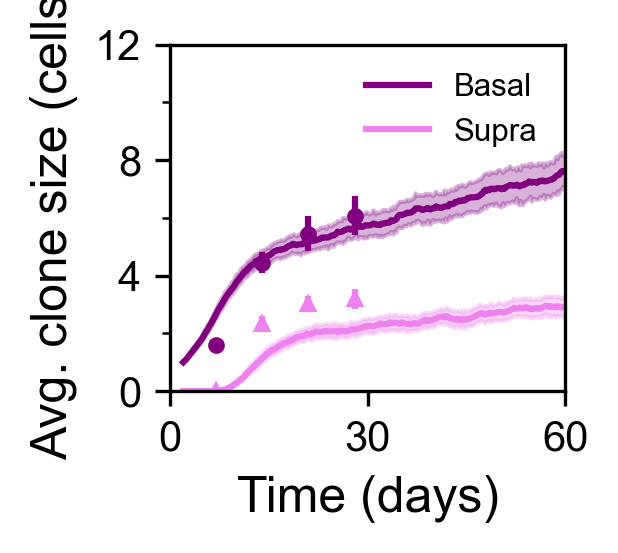

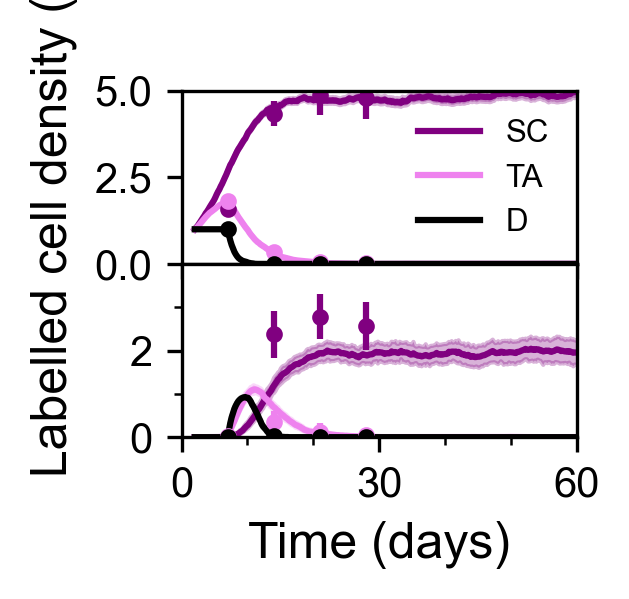

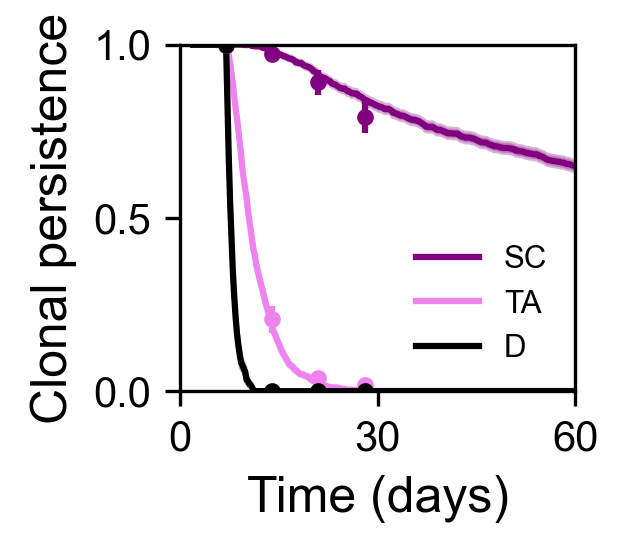

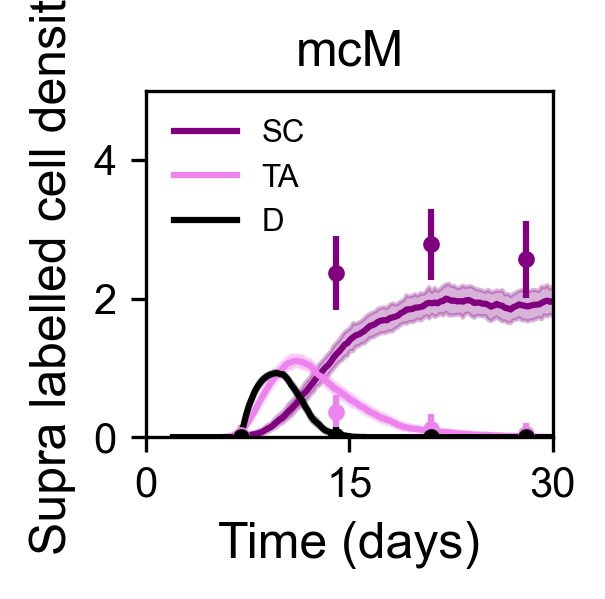

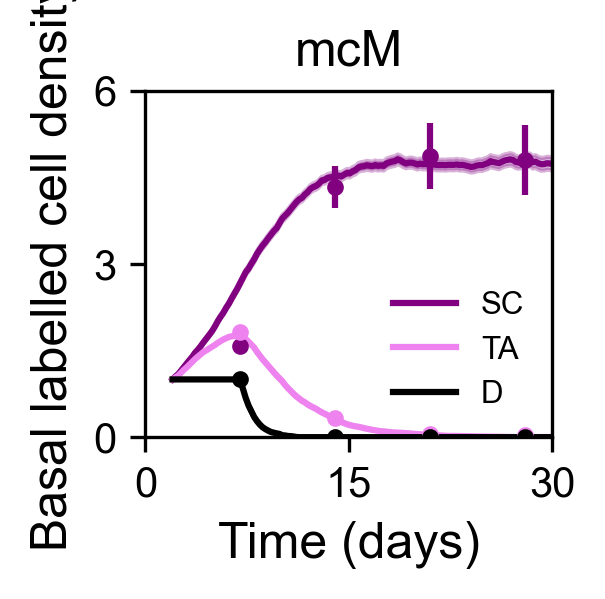

1 0 mcF
mcF 1447.6750267701952 ll_SPD
hrun_ST2D_0D_t_-30_n_1000_CVd_D_0.85_CVd_S_0.75_CVd_T_-1.0_corrDD_0.9_corrSS_1.0_corrST_1.0_corrTD_0.0_corrTT_-1.0_q_0.7_r_0.15_refractT_-1.0_rhoS_0.275_tau_100.0_seed_0.pkl
tscale: -4.05
τ range: 0.8666666666666667 to 140.0
shed: -0.85 refract: 0.0 cv: 1.0
Already cropped
Already cropped


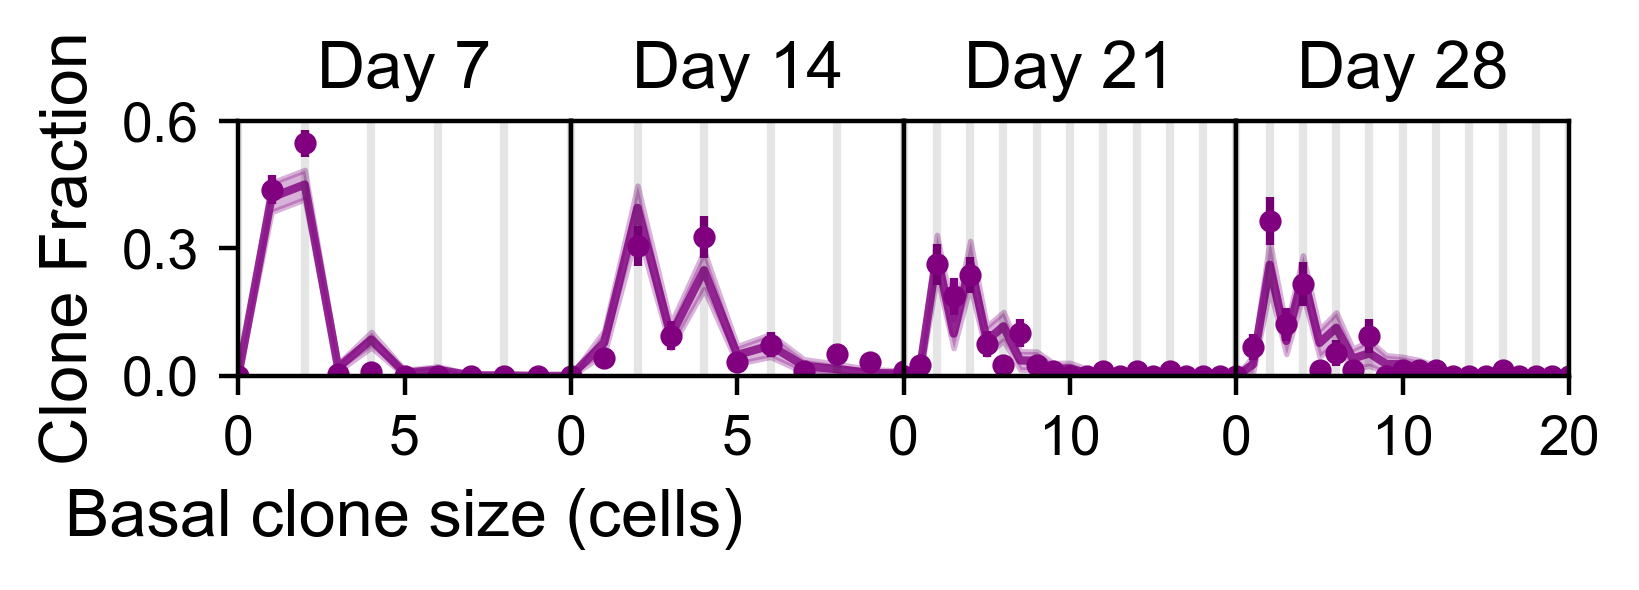

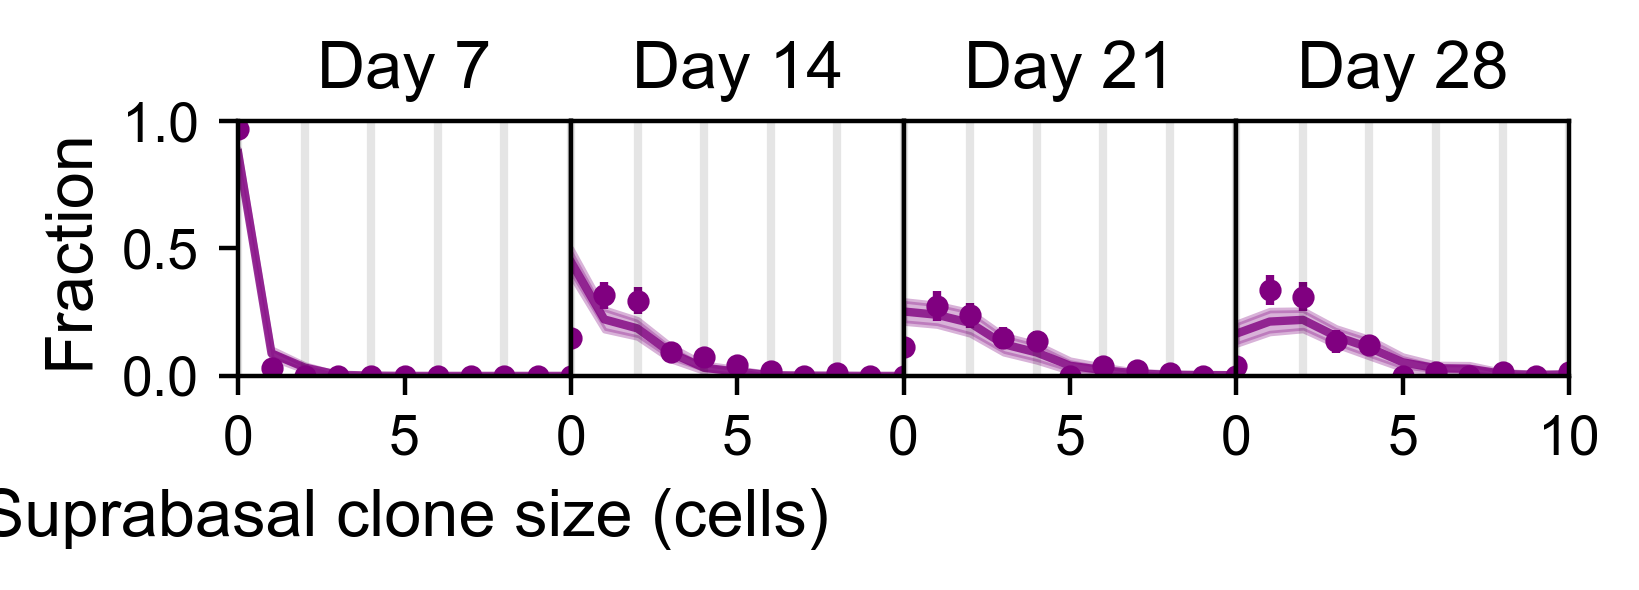

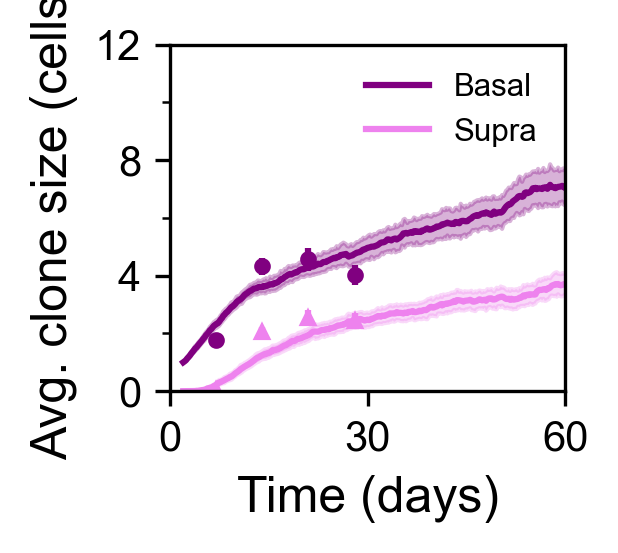

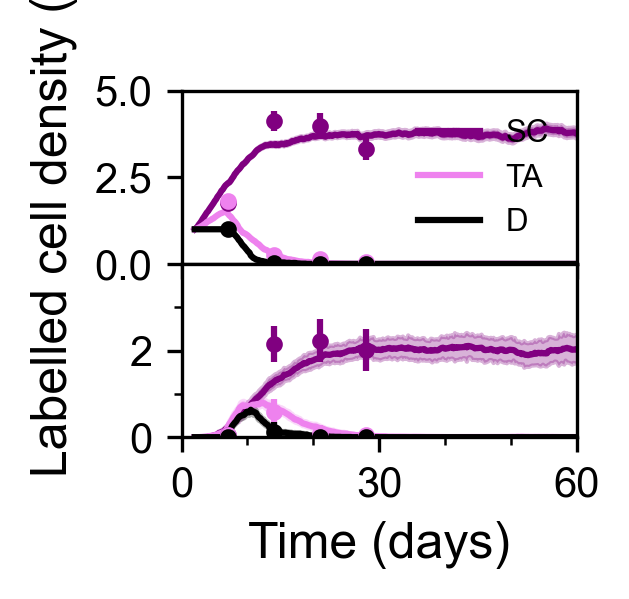

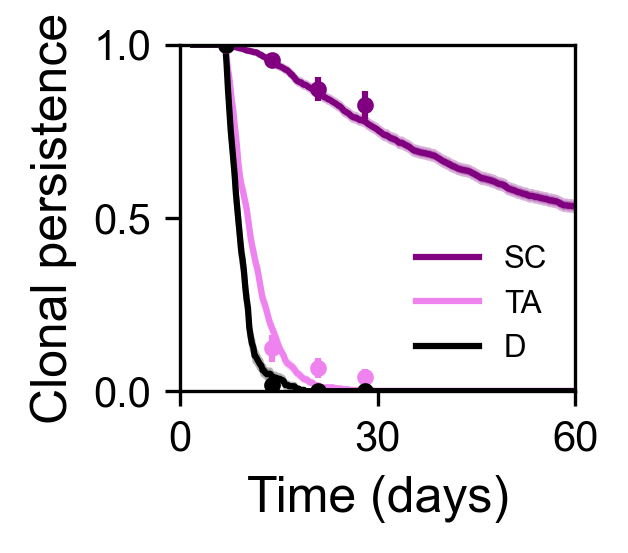

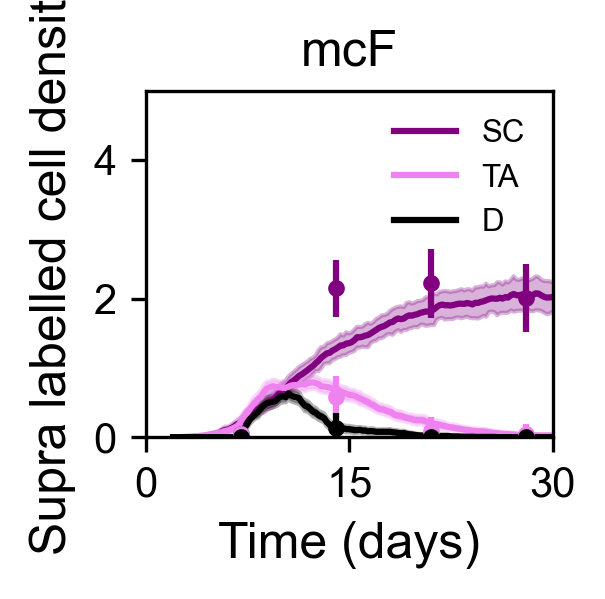

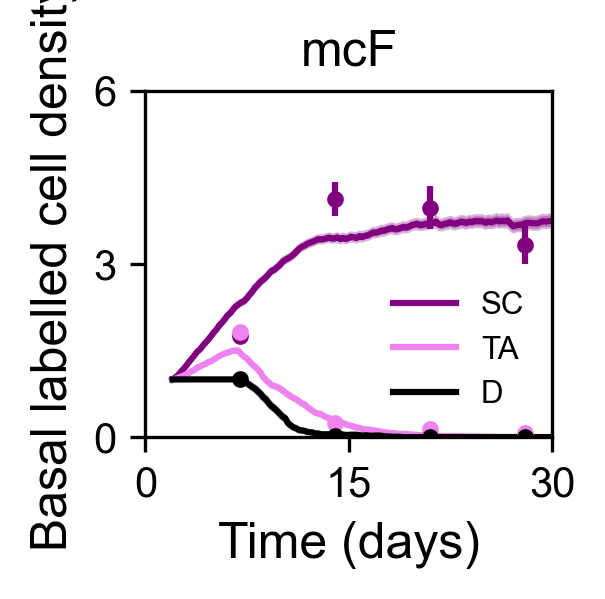

In [ ]:
'''  
    Simulated annealing
'''

ncells = 1000
tau = 100.0
cST = 1.0
cTD = 0.0
cvS = 1.0
L = 20
hilln = 0.0
ncores = 1
ncells1 = 5000


figfolder = 'Fig5_perturbed/'

cols = {'M': 'r', 'F': 'b', 'castre': 'purple', 'ovx': 'orange', 'mcM': 'purple', 'mcF': 'purple'}
sexname = {'M': 'M', 'F': 'F', 'castre': 'cM', 'ovx': 'ovx', 'mcM': 'mcM', 'mcF': 'mcF'}

sim_datasets = {}
sim_datasets_full = {}
exp_datasets = {}
best_fits = {}


for sex in ['ovx']:
    if sex == 'M':
        exp_file = '../../experiment/homeo/data_ctr_M.pkl'
        rhoS = 0.3
        cv_sb = 1.0
        q = 0.55
        r = 0.15
    elif sex == 'F':
        exp_file = '../../experiment/homeo/data_ctr_F.pkl'
        rhoS = 0.275
        cv_sb = 0.1   
        q = 1.0 #0.75
        r = 0.125
    elif sex == 'castre':
        exp_file = '../../experiment/castre/data_castre.pkl'
        rhoS = 0.275
        cv_sb = 1.0    
        q = 0.75
        r = 0.1
    elif sex == 'ovx': 
        exp_file = '../../experiment/ovx/data_Ovx.pkl'
        rhoS = 0.32
        cv_sb = 1.0
        q = 1.0
        r = 0.2
        tscale_inc_times = np.arange(1,5)

    for mode in [0]:
        print(ncores, mode, sex)

        if mode == 0:
            savefolder = 'modelling/ST2D_0D_finale/'
            nseeds = 1
            s0 = topt.sim_anneal(sim_model.ST2D_0D, { 'r': [r],
                                                'CVd_D': [1.0],
                                                'corrSS': [0.0],
                                                'corrDD': [0.0],
                                                'q': [q]},
                                params = {'tau': tau, 'refractT': -1, 'corrTT': -1.0,
                                        'CVd_T': -1.0, 'corrTD': cTD, 'rhoS': rhoS,
                                        'CVd_S': cvS, 'corrST':  cST}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate,
                        move_seed = np.abs(0),  use_linear = ['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrST', 'corrDD', 'corrSS'],
                        move_sizes =     {'r': 0.025, 'rhoS':  0.025, 'q': 0.025, 'CVd_S':  0.05, 'CVd_D':  0.05, 'corrST':  0.05, 'corrDD':  0.05, 'corrSS':  0.05},
                        free_param_min = {'r': 0.00, 'rhoS':   0.1, 'q':  0.0, 'CVd_S':  0.0, 'CVd_D':  0.0, 'corrST':  0.0, 'corrDD':  0.0, 'corrSS':  0.0},
                        free_param_max = {'r': 1.00, 'rhoS':   1.0, 'q':  1.01, 'CVd_S': 1.04, 'CVd_D': 1.04, 'corrST': 1.04, 'corrDD': 1.04, 'corrSS': 1.04})
        elif mode == 1:
            savefolder = 'modelling/ST2D_0D_finale/'
            nseeds = ncores
            s0 = topt.sim_anneal(sim_model.ST2D_size, { 'r': [r],
                                                'CVd_D': [1.0],
                                                'corrSS': [1.0],
                                                'corrDD': [1.0],
                                                'q': [q]},
                                params = {'tau': tau, 'refractT': -1, 'corrTT': -1.0,
                                        'CVd_T': -1.0, 'corrTD': cTD, 'rhoS': rhoS,
                                        'CVd_S': cvS, 'corrST':  cST, 
                                        'L': L, 'hilln': hilln}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate,
                        move_seed = np.abs(0),  use_linear = ['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrST', 'corrDD', 'corrSS'],
                        move_sizes =     {'r': 0.025, 'rhoS':  0.025, 'q': 0.025, 'CVd_S':  0.05, 'CVd_D':  0.05, 'corrST':  0.05, 'corrDD':  0.05, 'corrSS':  0.05},
                        free_param_min = {'r': 0.00, 'rhoS':   0.1, 'q':  0.0, 'CVd_S':  0.0, 'CVd_D':  0.0, 'corrST':  0.0, 'corrDD':  0.0, 'corrSS':  0.0},
                free_param_max = {'r': 1.00, 'rhoS':   1.0, 'q':  1.01, 'CVd_S': 1.04, 'CVd_D': 1.04, 'corrST': 1.04, 'corrDD': 1.04, 'corrSS': 1.04})
    
        s0.load_existing(tsteps = -30, ncells = ncells, savefolder = savefolder, 
                        tscalevals = -np.arange(4,15,0.05), shedvals = -np.arange(0.45, 0.95, 0.05), 
                        postopt_params = {'sbas_cv': [cv_sb]})
        
        
        for met in ['ll_SPD']: #, 'll_SPD', 'ksd_b_sb']: # 'll_STD', 'ksd_bas', 'ksd_b_sb'
            print(sex, s0.searchspace[met].min(), met)
            best_fits[(savefolder, sex, met)] = s0.best_fit(met)
            print(s0.sim_save_name(-30, ncells, int(best_fits[(savefolder, sex, met)].name), 0))
            
            if s0.searchspace[met].min() >= 1e10:
                print('Missing fit')
                continue
            
            #continue
            sim_data = s0.get_best_fit(met, -30, ncells1, savefolder = savefolder, nseeds = 1, 
                                       save_results = True, skip = 5, print_fit = False,
                                        norun = False)
            exp_data = s0.exp_data


            sim_datasets_full[sex] = sim_data
            sdt = sim_data.data_time_crop()
            sim_datasets[sex] = sdt
            exp_datasets[sex] = exp_data


            if sex == 'ovx':
                ncols = 5
            else:
                ncols = 6
            
            axs = ds.plot_dist('basalCS', sdt, exp_data, maxbin = 25, cdf = False, 
                   xlabel= 'Basal clone size (cells)', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=ncols, im_width = 1.05, ymax = 0.6, xmax = [10, 10, 20, 20,20,20],
                ylabel = 'Clone Fraction', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2))    

            plt.savefig(f'Figures/{figfolder}{sexname[sex]}basal_pdf_short_{sex}.pdf', dpi = 300)     


            axs = ds.plot_dist('supraCS', sdt, exp_data,  maxbin = 25, 
                            cdf = False, xlabel= 'Suprabasal clone size (cells)',
                                bootSEs=True, color = f'{cols[sex]}',
                            ncols=ncols, im_width = 1.05, ymax = 1.0, xmax = [10,10,10,10,10,20],
                                ylabel = 'Fraction', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True, 
                                yticks = [0, 0.5, 1.0], add_vlines = np.arange(0, 30, 2))  
            axs[0].legend(loc='upper right', frameon=False)
            #axs[4].legend(loc='upper right', frameon=False)
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}supra_pdf_short_{sex}.pdf', dpi = 300)      

            sec_cols = {'M': 'salmon', 'F': 'deepskyblue', 'castre': 'violet',
                        'ovx': 'mediumseagreen', 'mcM': 'violet', 'mcF': 'violet'}


            plt.figure(figsize = (1.7,1.5), dpi = 300)  
            ds.plot_quantity('S4like.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'Basal', color = cols[sex], xfmt = 'o', sfmt = '-')
            ds.plot_quantity('S4like.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Avg. clone size (cells)', plot_seeded = False, bootSEs = True, prelabel = 'Supra', color = sec_cols[sex], xfmt = '^', sfmt = '-')
            plt.xlim([0,60])
            plt.ylim([0,12])
            plt.yticks(np.arange(0, 13, 4))
            plt.yticks(np.arange(0, 13, 2), minor = True)
            plt.xticks(np.arange(0, 61, 30))
            plt.legend(frameon = False)
            #plt.title(fullsex[sex] + ': S-like (4+ cells)')
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_av_size_S4_{sex}.pdf', dpi = 300)
            plt.show() 


            plt.figure(figsize = (1.7,1.5), dpi = 300)
            plt.subplot(2,1,1)
            ds.plot_quantity('S4like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'SC', color =  cols[sex])

            ds.plot_quantity('CPlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = sec_cols[sex])           
            ds.plot_quantity('Dlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Labelled cell density (cells)', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            plt.ylim([0,5])
            plt.yticks(np.arange(0, 6, 2.5))
            #plt.yticks(np.arange(0, 6, 1), minor = True)
            plt.legend(frameon = False)
            plt.title('    ')
            plt.xlim([0,60])
            plt.xticks([0,60], minor = True)
            plt.xticks([0,60], minor = False, alpha = 0.0)
            #plt.xticks([])
            plt.xlabel('  ')

            #plt.show()
            plt.subplot(2,1,2)
            ds.plot_quantity('S4like.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'SC', color =  cols[sex], nolegend = True)
            ds.plot_quantity('CPlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = sec_cols[sex], nolegend = True)           
            ds.plot_quantity('Dlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Supra labelled cell density (cells)', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k', nolegend = True)    
            plt.ylim([0,4])
            plt.yticks(np.arange(0, 4, 2))
            plt.yticks(np.arange(0, 4, 1), minor = True)
            plt.xlim([0,60])
            plt.xticks(np.arange(0, 61, 30))
            plt.xticks(np.arange(0, 61, 10), minor = True)
            plt.ylabel('')
            plt.subplots_adjust(wspace=0, hspace=0)
            plt.tight_layout()

            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_labelled_cell_density_{sex}.pdf', dpi = 300)
            plt.show()             



            plt.figure(figsize = (1.7,1.5), dpi = 300)
            ds.plot_quantity('S4like.pers', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Persistence', plot_seeded = False, bootSEs = True, prelabel = 'SC', color =  cols[sex])
            ds.plot_quantity('CPlike.pers', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Persistence', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = sec_cols[sex])
            ds.plot_quantity('Dlike.pers', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Clonal persistence', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            #plt.title(fullsex[sex])
            plt.xlim([0,60])
            plt.ylim([0,1])
            plt.yticks(np.arange(0, 1.1, 0.5))
            plt.xticks(np.arange(0, 61, 30))
            plt.legend(frameon = False)
            #plt.title(fullsex[sex])
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_persistence_{sex}.pdf', dpi = 300)
            plt.show() 


            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('S4like.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'SC',color =  cols[sex])
            #ds.plot_quantity('T3like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
            #                ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'T3', color = 'tab:orange')
            ds.plot_quantity('CPlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = sec_cols[sex])   
            ds.plot_quantity('Dlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Supra labelled cell density', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            #plt.title(dataset[didx])
            plt.xlim([0,30])
            plt.ylim([0,5])
            plt.xticks(np.arange(0, 31, 15))
            plt.legend(frameon = False)
            plt.title(sex)
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_supra_lcd_{sex}.pdf', dpi = 300, bbox_inches = 'tight')
            plt.show()             


            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('S4like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'SC', color =  cols[sex])
            #ds.plot_quantity('T3like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
            #                ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'T3', color = 'tab:orange')
            ds.plot_quantity('CPlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = sec_cols[sex])   
            ds.plot_quantity('Dlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Basal labelled cell density', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            #plt.title(dataset[didx])
            plt.xlim([0,30])
            plt.ylim([0,6])
            plt.yticks(np.arange(0, 7, 3))
            plt.xticks(np.arange(0, 31, 15))
            plt.legend(frameon = False)
            plt.title(sex)
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_basal_lcd_{sex}.pdf', dpi = 300, bbox_inches = 'tight')
            plt.show()

In [ ]:
for met in ['ll_SPD']: #, 'ksd_b_sb', 'full'
    for sex in ['ovx']:
        params = best_fits[(savefolder, sex, met)]
        params['tau'] = - params[met + ':tscale']
        params['mu'] = ((params['q']-2)*params['rhoS']*params['tau'] + params['tau']*(1-params['rhoS']))/(params['rhoS']*(3-params['q']))#/params['tau']*params['tscale']
        params['rhoT1'] = params['tau']/(params['tau'] + ((3 - params['q'])*params['mu'] + (2 - params['q'])*params['tau']))
        params['rhoT2'] = params['tau']*(1-params['q'])/(params['tau'] + ((3 - params['q'])*params['mu'] + (2 - params['q'])*params['tau']))
        params['rhoD'] = params['mu']*(3-params['q'])/(params['tau'] + ((3 - params['q'])*params['mu'] + (2 - params['q'])*params['tau']))
        params['rhoT'] = params['rhoT1'] + params['rhoT2']
        print(sex, met)
        print(params[['tscale', 'mu', 'shed', 'r', 'q', 'rhoS', 'rhoT1', 'rhoT2', 'rhoD', 'rhoT', 'CVd_S', 'CVd_D', 'corrST', 'corrTD', 'corrDD', 'corrSS']])

ovx ll_SPD
tscale       -5.45
mu        2.036264
shed          -0.6
r            0.225
q            0.725
rhoS          0.32
rhoT1         0.32
rhoT2        0.088
rhoD         0.272
rhoT         0.408
CVd_S          0.5
CVd_D          0.9
corrST         1.0
corrTD         0.0
corrDD         0.5
corrSS         0.4
Name: 913, dtype: object
mcM ll_SPD
tscale      -4.15
mu        5.14972
shed         -0.9
r             0.1
q           0.875
rhoS         0.21
rhoT1        0.21
rhoT2     0.02625
rhoD      0.55375
rhoT      0.23625
CVd_S        0.75
CVd_D        0.25
corrST        1.0
corrTD        0.0
corrDD        0.7
corrSS        0.7
Name: 17997, dtype: object
mcF ll_SPD
tscale       -4.05
mu        2.353162
shed         -0.85
r             0.15
q              0.7
rhoS         0.275
rhoT1        0.275
rhoT2       0.0825
rhoD        0.3675
rhoT        0.3575
CVd_S         0.75
CVd_D         0.85
corrST         1.0
corrTD         0.0
corrDD         0.9
corrSS         1.0
Name: 23087, dtype:

In [ ]:
best_fits[(savefolder, sex, met)]

index                       226
r                          0.15
corrSS                      0.4
corrDD                      0.7
q                          0.45
CVd_D                      0.85
tau                       100.0
refractT                     -1
corrTT                     -1.0
CVd_T                      -1.0
corrTD                      0.0
rhoS                       0.21
corrST                      1.0
CVd_S                       0.4
maxseed                       1
ll_SPD              1560.728718
ll_SPD:shed               -0.75
ll_SPD:tscale              -4.0
ll_STD              1715.693654
ll_STD:shed                -0.7
ll_STD:tscale              -4.0
ksd_b_sb               1.140396
ksd_b_sb:shed              -0.9
ksd_b_sb:tscale            -4.0
ksd_bas                0.649923
ksd_bas:shed               -0.9
ksd_bas:tscale             -4.0
ll_S_bas              604.33493
ll_S_bas:shed              -0.9
ll_S_bas:tscale            -4.0
full                1382.786269
full:she